# 02 - Feature engineering, model development and selection
This notebook explains the modelling choices. The *tracked, reproducible* run is
`python -m cardiorisk.train` (all runs logged to MLflow); here we inspect what it produced and
re-derive the key decisions.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("CARDIORISK_ROOT", str(ROOT))
print("project root:", ROOT)

project root: /home/claude/heart-disease-mlops


In [2]:
import json, pandas as pd, numpy as np
from cardiorisk import config
from cardiorisk.data import load_clean
from cardiorisk.features import build_pipeline, build_preprocessor, split_xy
df = load_clean(); X, y = split_xy(df)
prep = build_preprocessor().fit(X)
names = prep.named_steps["columns"].get_feature_names_out()
print(len(names), "model features after engineering + encoding:")
print(list(names))

36 model features after engineering + encoding:
['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'num__hr_reserve_pct', 'num__age_x_oldpeak', 'cat__sex_0.0', 'cat__sex_1.0', 'cat__cp_1.0', 'cat__cp_2.0', 'cat__cp_3.0', 'cat__cp_4.0', 'cat__fbs_-1.0', 'cat__fbs_0.0', 'cat__fbs_1.0', 'cat__restecg_-1.0', 'cat__restecg_0.0', 'cat__restecg_1.0', 'cat__restecg_2.0', 'cat__exang_-1.0', 'cat__exang_0.0', 'cat__exang_1.0', 'cat__slope_-1.0', 'cat__slope_1.0', 'cat__slope_2.0', 'cat__slope_3.0', 'cat__ca_-1.0', 'cat__ca_0.0', 'cat__ca_1.0', 'cat__ca_2.0', 'cat__ca_3.0', 'cat__thal_-1.0', 'cat__thal_3.0', 'cat__thal_6.0', 'cat__thal_7.0']


## Candidate models and tuning
Three families, each tuned with `GridSearchCV` (stratified 5-fold, refit on ROC-AUC) - grids in `params.yaml`:

| family | why | grid |
|---|---|---|
| Logistic Regression | interpretable baseline, calibrated probabilities | C, L1/L2, class_weight (24) |
| Random Forest | non-linear interactions, robust to scaling | depth, leaf size, max_features (24) |
| HistGradientBoosting | strong tabular learner, native NaN support | learning rate, depth, L2, leaf size (24) |

Selection uses **cross-validated ROC-AUC on the training split only** - the 20% hold-out test set is touched once, for the final report.

In [3]:
m = json.loads((config.REPORTS_DIR / "metrics.json").read_text())
rows = []
for name, r in m["models"].items():
    rows.append({"model": name, **{k: r[k] for k in ["cv_roc_auc_mean","cv_roc_auc_std","cv_accuracy_mean","cv_precision_mean",
                 "cv_recall_mean","cv_f1_mean","overfit_gap_roc_auc","test_roc_auc","test_accuracy"]}})
pd.DataFrame(rows).set_index("model").round(4)

,cv_roc_auc_mean,cv_roc_auc_std,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,overfit_gap_roc_auc,test_roc_auc,test_accuracy
model,,,,,,,,,
logistic_regression,0.9049,0.0136,0.8351,0.8526,0.8497,0.8506,0.0114,0.8995,0.8424
random_forest,0.8949,0.0214,0.8228,0.8355,0.8471,0.8407,0.0662,0.8881,0.8424
gradient_boosting,0.8912,0.0199,0.8201,0.8300,0.8521,0.8401,0.0558,0.8938,0.8424


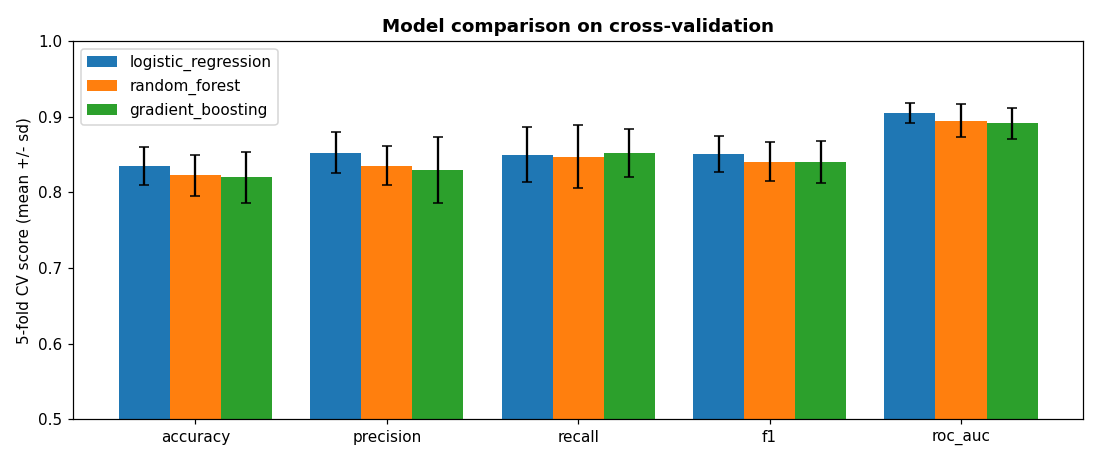

logistic_regression    best params: {'C': 0.3, 'class_weight': 'None', 'penalty': 'l1'}
random_forest          best params: {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 3}
gradient_boosting      best params: {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 10}


In [4]:
from IPython.display import Image, display
display(Image(filename=str(config.FIGURES_DIR / "model_model_comparison.png")))
for k, r in m["models"].items(): print(f"{k:22s} best params: {r['best_params']}")

**Champion: L1-regularised logistic regression.** Highest CV ROC-AUC, lowest variance across folds and by far the
smallest train/validation gap (the tree models overfit a 734-row training set). It is also explainable to a clinician.

## Decision threshold
A screening model should miss few sick patients, so the threshold maximises **F2** (recall weighted 2x) on
*out-of-fold* predictions, subject to a false-alarm budget of specificity >= 0.70.

In [5]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from cardiorisk.evaluate import classification_metrics
meta = json.loads(config.METADATA_PATH.read_text())
strata = df["source"] + "_" + df["target"].astype(str)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=strata, random_state=42)
p = meta["best_params"]
lr = build_pipeline(LogisticRegression(C=p["C"], penalty=p["penalty"], solver="liblinear", max_iter=5000))
oof = cross_val_predict(lr, Xtr, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]
tab = pd.DataFrame([{"threshold": t, **{k: v for k, v in classification_metrics(ytr, oof, t).items()
                     if k in ("recall","specificity","precision","f2","accuracy")}} for t in np.arange(0.25, 0.66, 0.05)])
print("chosen threshold:", meta["decision_threshold"]); tab.round(3)

chosen threshold: 0.39


,threshold,accuracy,precision,recall,specificity,f2
0,0.25,0.781,0.728,0.963,0.555,0.905
1,0.30,0.796,0.748,0.951,0.604,0.902
2,0.35,0.811,0.775,0.926,0.668,0.891
3,0.40,0.823,0.797,0.911,0.713,0.886
4,0.45,0.828,0.823,0.879,0.765,0.867
5,0.50,0.835,0.852,0.850,0.817,0.850
6,0.55,0.837,0.874,0.823,0.854,0.833
7,0.60,0.827,0.882,0.793,0.869,0.809
8,0.65,0.816,0.890,0.761,0.884,0.784


## Hold-out test results of the champion

In [6]:
pd.Series(meta["test_metrics"]).round(4)

test_accuracy        0.8315
test_precision       0.8087
test_recall          0.9118
test_specificity     0.7317
test_f1              0.8571
test_f2              0.8891
test_roc_auc         0.8995
test_pr_auc          0.9126
test_brier           0.1234
test_tp             93.0000
test_fp             22.0000
test_tn             60.0000
test_fn              9.0000
dtype: float64

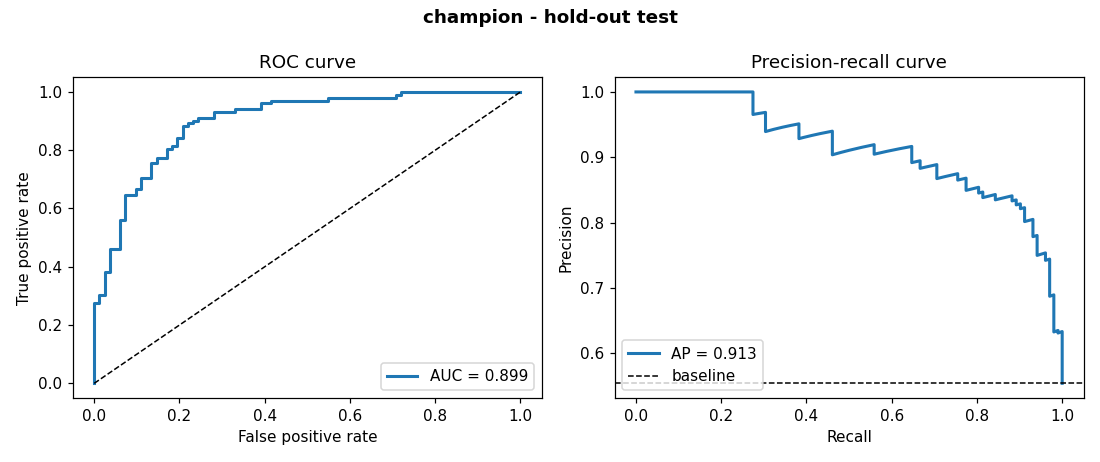

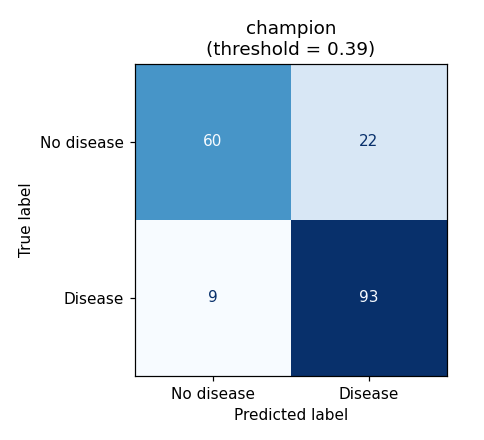

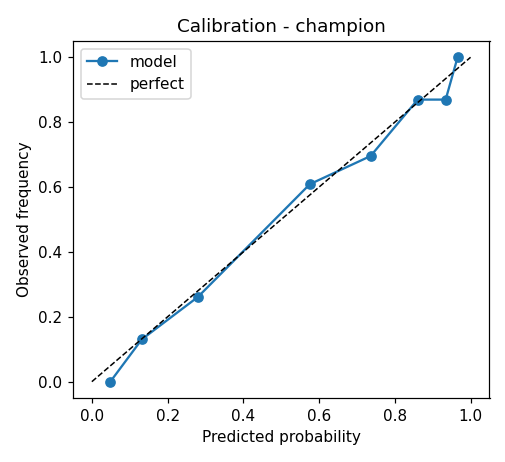

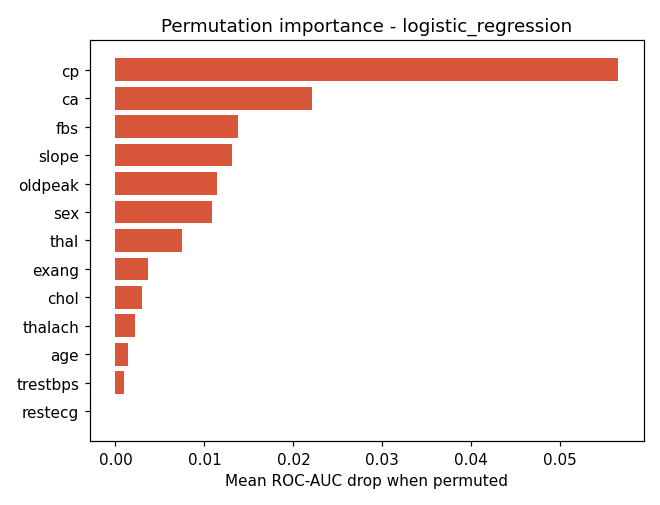

In [7]:
for f in ["model_champion_roc_pr.png","model_champion_confusion.png","model_champion_calibration.png","model_champion_permutation_importance.png"]:
    display(Image(filename=str(config.FIGURES_DIR / f)))

## Robustness: per-hospital test performance and the missing-indicator ablation

In [8]:
display(pd.DataFrame(m["per_site_test"]).T)
pd.Series(m["ablation_missing_indicators"])

,accuracy,precision,recall,roc_auc,n
cleveland,0.8852,0.8182,0.9643,0.9600,61.0
hungarian,0.7759,0.6667,0.7619,0.8597,58.0
switzerland,0.9200,0.9565,0.9565,0.7609,25.0
va_long_beach,0.7750,0.8000,0.9333,0.6967,40.0


oof_roc_auc_with_indicators       0.9045
oof_roc_auc_without_indicators    0.9044
test_roc_auc_with_indicators      0.9034
dtype: float64

Indicators add essentially nothing (OOF ROC-AUC difference of about 0.0001), which supports leaving them out: same accuracy and less reliance on
site artefacts. Per-site ROC-AUC is lowest for VA Long Beach and Switzerland, where `ca`/`thal`/`chol` are mostly
missing - an honest limitation recorded in the report.